<a href="https://colab.research.google.com/github/jeej11200-create/ARTI502_Assignment2/blob/main/ARTI502_Assignment2_CIFAR10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment2: Training & Testing CNN with CIFAR-10 Dataset
---
**Group #2**

### Group Members
| # | Member Name | Member Academic ID |
|:---:|:------------------|:------------------:|
| 1 | Arwa Alqahtani | 2230007398 |
| 2 | Mashaal Alqahtani | 2230006753 |
| 3 | Tayma Aldobas | 2230006269 |
| 4 | Jana Algahtani | 2230003732 |
| 5 | Nora Alqahtani | 2230002963 |

## Task 1: Getting the CIFAR Dataset

- Import the required libraries for loading the dataset, building CNN models, and visualizing results
- Download the CIFAR-10 dataset and verify that the training and testing sets are loaded successfully

In [ ]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

DATA_PATH = "./cifar_data"

train_data = datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_data = datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

print("Dataset loaded successfully")
print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Classes:", train_data.classes)

100%|██████████| 170M/170M [58:36<00:00, 48.5kB/s]


Dataset loaded successfully
Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Task 2: Defining the Network

- Check whether a GPU is available for model training

- Build a simple convolutional neural network using convolutional layers, max-pooling, and fully connected layers.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = SimpleCNN()
print(model)

Device: cpu
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


- Define a function that trains the CNN model for one epoch and calculates the average training loss

- Evaluate the trained CNN using test data and calculate test loss and accuracy.

In [ ]:
# Training Function
def train_one_epoch(model, data_loader, loss_function, optimizer):

    model.train()
    total_loss = 0

    for images, labels in data_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(data_loader.dataset)


# Testing Function
def test_model(model, data_loader, loss_function):

    model.eval()
    total_loss = 0
    correct = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = loss_function(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()

    test_loss = total_loss / len(data_loader.dataset)

    test_accuracy = 100 * correct / len(data_loader.dataset)

    return test_loss, test_accuracy

## Task 3: Loading Data

Load image batches and print the tensor dimensions & Display sample CIFAR-10 images using Matplotlib

Images tensor size: torch.Size([64, 3, 32, 32])
Labels tensor size: torch.Size([64])


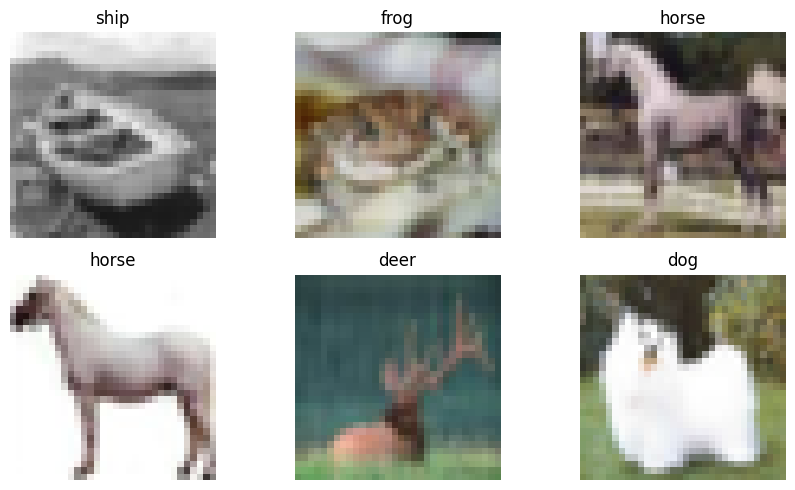

In [ ]:
# DataLoader and Tensor Size
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

# Image Visualization
plt.figure(figsize=(9, 5))

for i in range(6):

    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i].permute(1, 2, 0))

    plt.title(train_data.classes[labels[i].item()])

    plt.axis("off")

plt.tight_layout()
plt.show()


##Task 4: Dataset Augmentation

- Convert an image tensor back into PIL format

- Define a transformation that adds Gaussian noise to training images

- Apply multiple data augmentation techniques to training images while keeping test images unchanged except for normalization.


Converted image type: <class 'PIL.Image.Image'>


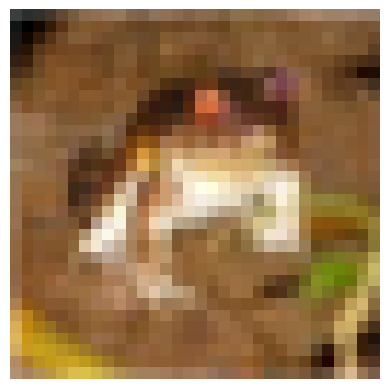

In [ ]:
# ToPILImage

tensor_image = train_data[0][0]

pil_image = transforms.ToPILImage()(tensor_image)

print("Converted image type:", type(pil_image))

plt.imshow(pil_image)
plt.axis("off")
plt.show()

# adding noise function
class AddNoise:

    def __call__(self, image):

        noise = torch.randn_like(image) * 0.02

        return torch.clamp(image + noise, 0, 1)

# Define Augmentation Transforms
train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(),

    transforms.RandomResizedCrop(
        32,
        scale=(0.85, 1.0)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    AddNoise(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

- Prepare training and testing datasets with appropriate transformations

- Display sample images after applying data augmentation


Baseline batches: 782
Augmented batches: 391
Test batches: 79


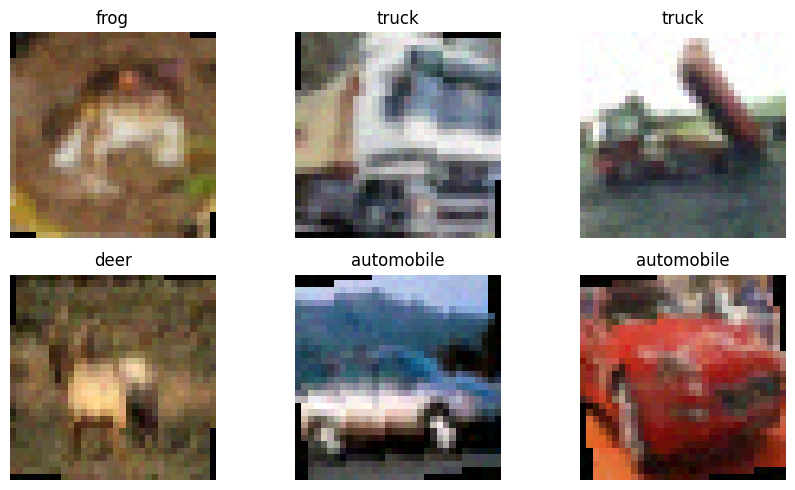

In [ ]:
# Create Augmented DataLoaders

baseline_data = datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=test_transform
)

augmented_data = datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform
)

normalized_test_data = datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

baseline_loader = DataLoader(
    baseline_data,
    batch_size=64,
    shuffle=True
)

augmented_loader = DataLoader(
    augmented_data,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    normalized_test_data,
    batch_size=128,
    shuffle=False
)

print("Baseline batches:", len(baseline_loader))
print("Augmented batches:", len(augmented_loader))
print("Test batches:", len(test_loader))

# Visualize Augmented Images
plt.figure(figsize=(9, 5))

for i in range(6):

    image, label = augmented_data[i]

    image = (image * 0.5 + 0.5).clamp(0, 1)

    plt.subplot(2, 3, i + 1)

    plt.imshow(image.permute(1, 2, 0))

    plt.title(augmented_data.classes[label])

    plt.axis("off")

plt.tight_layout()
plt.show()


## Task 5: Training & Hyperparameter Tuning


Define a second CNN architecture with more convolutional layers for comparison.

In [ ]:
class LargerCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x


print(LargerCNN())

LargerCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


Train SimpleCNN using the baseline dataset and record training and testing metrics

In [ ]:
# Train Experiment 1

model1 = SimpleCNN().to(device)

loss_function = nn.CrossEntropyLoss()

optimizer1 = optim.Adam(
    model1.parameters(),
    lr=0.001
)

epochs1 = 5

train_losses1 = []
test_losses1 = []
test_accuracies1 = []

for epoch in range(epochs1):

    train_loss = train_one_epoch(
        model1,
        baseline_loader,
        loss_function,
        optimizer1
    )

    test_loss, accuracy = test_model(
        model1,
        test_loader,
        loss_function
    )

    train_losses1.append(train_loss)
    test_losses1.append(test_loss)
    test_accuracies1.append(accuracy)

    print(
        f"Exp 1 | Epoch {epoch + 1}/{epochs1} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {accuracy:.2f}%"
    )

Exp 1 | Epoch 1/5 | Train Loss: 1.4352 | Test Loss: 1.1912 | Test Accuracy: 57.92%
Exp 1 | Epoch 2/5 | Train Loss: 1.0836 | Test Loss: 1.1014 | Test Accuracy: 61.34%
Exp 1 | Epoch 3/5 | Train Loss: 0.9409 | Test Loss: 0.9637 | Test Accuracy: 66.09%
Exp 1 | Epoch 4/5 | Train Loss: 0.8463 | Test Loss: 0.9928 | Test Accuracy: 65.01%
Exp 1 | Epoch 5/5 | Train Loss: 0.7640 | Test Loss: 0.9066 | Test Accuracy: 68.16%


In [ ]:
# Train Experiment 2

model2 = LargerCNN().to(device)

optimizer2 = optim.Adam(
    model2.parameters(),
    lr=0.0005
)

epochs2 = 8

train_losses2 = []
test_losses2 = []
test_accuracies2 = []

for epoch in range(epochs2):

    train_loss = train_one_epoch(
        model2,
        augmented_loader,
        loss_function,
        optimizer2
    )

    test_loss, accuracy = test_model(
        model2,
        test_loader,
        loss_function
    )

    train_losses2.append(train_loss)
    test_losses2.append(test_loss)
    test_accuracies2.append(accuracy)

    print(
        f"Exp 2 | Epoch {epoch + 1}/{epochs2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {accuracy:.2f}%"
    )

Exp 2 | Epoch 1/8 | Train Loss: 1.6670 | Test Loss: 1.4108 | Test Accuracy: 49.57%
Exp 2 | Epoch 2/8 | Train Loss: 1.3738 | Test Loss: 1.2411 | Test Accuracy: 55.71%
Exp 2 | Epoch 3/8 | Train Loss: 1.2321 | Test Loss: 1.0924 | Test Accuracy: 61.28%
Exp 2 | Epoch 4/8 | Train Loss: 1.1335 | Test Loss: 1.0354 | Test Accuracy: 63.39%
Exp 2 | Epoch 5/8 | Train Loss: 1.0551 | Test Loss: 0.9695 | Test Accuracy: 65.62%
Exp 2 | Epoch 6/8 | Train Loss: 0.9949 | Test Loss: 0.9027 | Test Accuracy: 68.12%
Exp 2 | Epoch 7/8 | Train Loss: 0.9455 | Test Loss: 0.8664 | Test Accuracy: 70.36%
Exp 2 | Epoch 8/8 | Train Loss: 0.9043 | Test Loss: 0.8579 | Test Accuracy: 70.46%


In [ ]:
# Compare Final Results

print("Experiment 1 — SimpleCNN / No Augmentation")

print(f"Final Train Loss: {train_losses1[-1]:.4f}")
print(f"Final Test Loss: {test_losses1[-1]:.4f}")
print(f"Final Test Accuracy: {test_accuracies1[-1]:.2f}%")

print("\nExperiment 2 — LargerCNN / Augmentation")

print(f"Final Train Loss: {train_losses2[-1]:.4f}")
print(f"Final Test Loss: {test_losses2[-1]:.4f}")
print(f"Final Test Accuracy: {test_accuracies2[-1]:.2f}%")

if test_accuracies1[-1] >= test_accuracies2[-1]:
    print("\nBest final test accuracy: Experiment 1")
else:
    print("\nBest final test accuracy: Experiment 2")

Experiment 1 — SimpleCNN / No Augmentation
Final Train Loss: 0.7640
Final Test Loss: 0.9066
Final Test Accuracy: 68.16%

Experiment 2 — LargerCNN / Augmentation
Final Train Loss: 0.9043
Final Test Loss: 0.8579
Final Test Accuracy: 70.46%

Best final test accuracy: Experiment 2


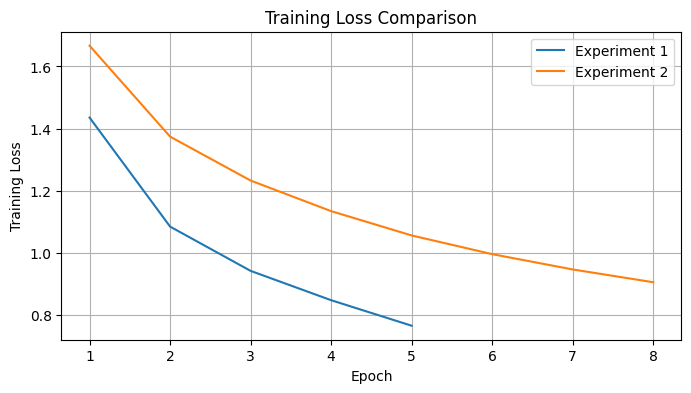

In [ ]:
# Training Loss Plot
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, epochs1 + 1),
    train_losses1,
    label="Experiment 1"
)

plt.plot(
    range(1, epochs2 + 1),
    train_losses2,
    label="Experiment 2"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")

plt.legend()
plt.grid(True)
plt.show()

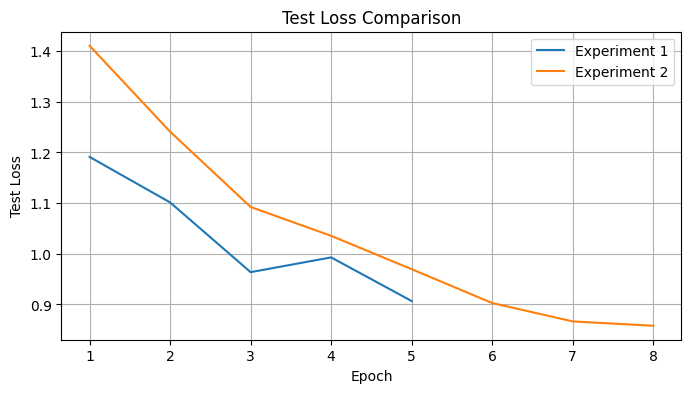

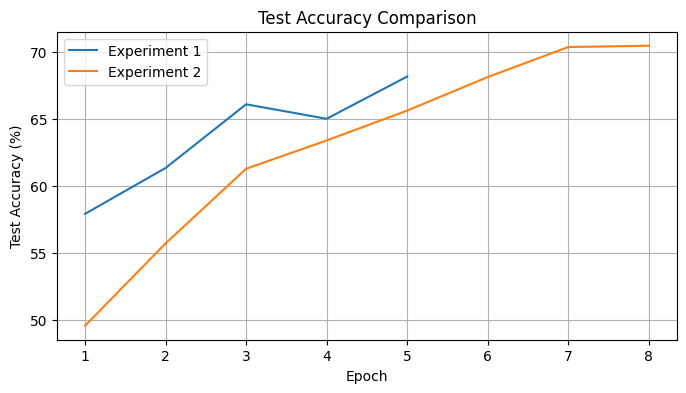

In [ ]:
# Testing Loss Plot

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, epochs1 + 1),
    test_losses1,
    label="Experiment 1"
)

plt.plot(
    range(1, epochs2 + 1),
    test_losses2,
    label="Experiment 2"
)

plt.xlabel("Epoch")
plt.ylabel("Test Loss")
plt.title("Test Loss Comparison")

plt.legend()
plt.grid(True)
plt.show()

# Testing Accuracy Plot

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, epochs1 + 1),
    test_accuracies1,
    label="Experiment 1"
)

plt.plot(
    range(1, epochs2 + 1),
    test_accuracies2,
    label="Experiment 2"
)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")

plt.legend()
plt.grid(True)
plt.show()